# ALS implicit — ranking validation (validation-first)

This notebook is **self-contained**: every piece of matrix construction, model
training, and evaluation logic lives inline below (no `src/` split). The only shared
import is the raw ratings loader `movielens.data.load_ratings`.

Implicit-feedback ALS over the ratings matrix (positive = `rating >= 4`,
confidence = `1 + 40 * rating`, unobserved = `0`), trained on a chronological
80/10/10 split and evaluated with `NDCG@10` (primary), `precision@10`,
`recall@10`, and `hit-rate@10` against the `xgboost-v1` @ `test` alias (v8) and an
inline popularity floor. The trained model is logged to MLflow under the **`test`**
alias with registry name `als-v1`.


In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import hashlib
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "movielens").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
from implicit.als import AlternatingLeastSquares

from movielens.data import RAW_DIR, load_ratings

SEED = 42
K = 10
FACTORS = 64
ALPHA = 40
REGULARIZATION = 0.1
ITERATIONS = 15
NUM_THREADS = 1
DTYPE = "float32"
EXPERIMENT = "als"
REGISTRY_NAME = "als-v1"
MLFLOW_URI = (ROOT / "mlflow" / "mlruns").as_uri()

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")

plt.rcParams["figure.figsize"] = (8, 3.5)


2026/10/17 22:05:38 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [2]:
def data_version_hash():
    digest = hashlib.sha1((RAW_DIR / "ratings.dat").read_bytes()).hexdigest()
    return digest[:12]


def git_sha():
    out = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return out.stdout.strip()


def precision_at_k(relevant, recommended, k=K):
    return float(np.mean([len(set(rec[:k]) & rel) / k for rel, rec in zip(relevant, recommended)]))


def recall_at_k(relevant, recommended, k=K):
    return float(
        np.mean([len(set(rec[:k]) & rel) / len(rel) if rel else 0.0 for rel, rec in zip(relevant, recommended)])
    )


def ndcg_at_k(relevant, recommended, k=K):
    vals = []
    for rel, rec in zip(relevant, recommended):
        dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(rec[:k]) if item in rel)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(rel))))
        vals.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(vals))


def hit_rate_at_k(relevant, recommended, k=K):
    return float(np.mean([1.0 if (set(rec[:k]) & rel) else 0.0 for rel, rec in zip(relevant, recommended)]))


## 1. EDA

Dataset shape, sparsity, the positive-vs-unobserved imbalance, the raw rating
distribution, and the implicit signal (`rating >= 4` vs non-positive/unobserved).


n_users: 6040
n_movies: 3706
n_ratings: 1000209
sparsity (observed / users x movies): 0.0447
positive cells (rating >= 4): 575281
positive ratio: 0.5752
imbalance (positive / non-positive): 1.35
full-matrix cells: 22384240
unobserved cells: 21384031


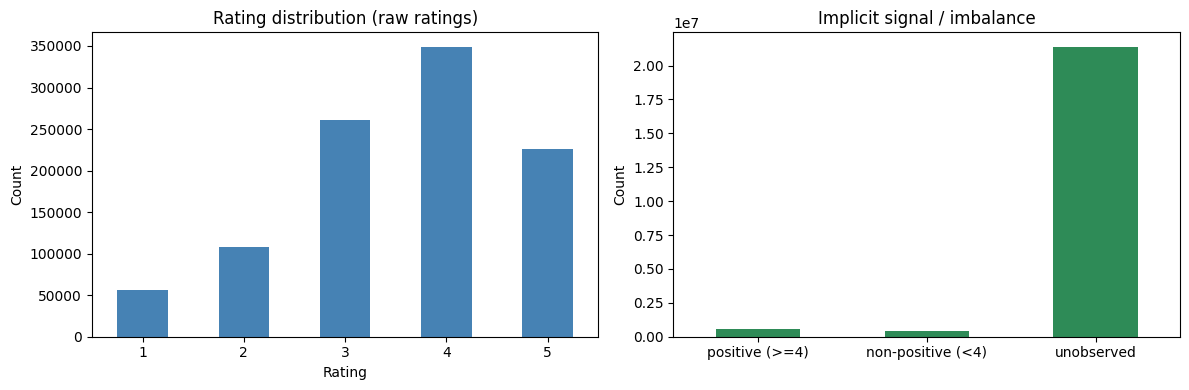

In [3]:
ratings = load_ratings()

n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)
sparsity = n_ratings / (n_users * n_movies)
n_positive = int((ratings["rating"] >= 4).sum())

print("n_users:", n_users)
print("n_movies:", n_movies)
print("n_ratings:", n_ratings)
print("sparsity (observed / users x movies):", round(sparsity, 4))
print("positive cells (rating >= 4):", n_positive)
print("positive ratio:", round(n_positive / n_ratings, 4))
print("imbalance (positive / non-positive):", round(n_positive / (n_ratings - n_positive), 2))
print("full-matrix cells:", n_users * n_movies)
print("unobserved cells:", n_users * n_movies - n_ratings)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Rating distribution (raw ratings)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

signal = pd.Series(
    [n_positive, n_ratings - n_positive, n_users * n_movies - n_ratings],
    index=["positive (>=4)", "non-positive (<4)", "unobserved"],
)
signal.plot(kind="bar", ax=axes[1], color="seagreen", rot=0)
axes[1].set_title("Implicit signal / imbalance")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 2. Implicit confidence matrix + chronological split

Sort by `timestamp` (stable), split globally 80/10/10, and build the train-only
confidence matrix (observed `1 + 40 * rating`, unobserved `0`).


In [4]:
user_ids = np.sort(ratings["user_id"].unique())
movie_ids = np.sort(ratings["movie_id"].unique())
user_index = {int(u): i for i, u in enumerate(user_ids)}
movie_index = {int(m): i for i, m in enumerate(movie_ids)}

df = ratings.sort_values(["timestamp", "user_id", "movie_id"], kind="stable").reset_index(drop=True)
n = len(df)
train_end = int(0.8 * n)
val_end = int(0.9 * n)
train = df.iloc[:train_end]
val = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

print("split sizes train/val/test:", len(train), len(val), len(test))
print("max train timestamp <= min val timestamp:",
      int(train["timestamp"].max()) <= int(val["timestamp"].min()))
print("max val timestamp <= min test timestamp:",
      int(val["timestamp"].max()) <= int(test["timestamp"].min()))

rows = train["user_id"].map(user_index).to_numpy(dtype=np.int32)
cols = train["movie_id"].map(movie_index).to_numpy(dtype=np.int32)
data = (1 + ALPHA * train["rating"]).to_numpy(dtype=np.float32)
confidence = sparse.csr_matrix((data, (rows, cols)), shape=(n_users, n_movies))

print("confidence matrix shape:", confidence.shape, "nnz:", confidence.nnz)
print("4-star confidence == 161:", bool((data == 161).any()))
print("5-star confidence == 201:", bool((data == 201).any()))
print("unobserved cells are 0 (matrix has only train observations):", confidence.nnz == len(train))


split sizes train/val/test: 800167 100021 100021
max train timestamp <= min val timestamp: True
max val timestamp <= min test timestamp: True
confidence matrix shape: (6040, 3706) nnz: 800167
4-star confidence == 161: True
5-star confidence == 201: True
unobserved cells are 0 (matrix has only train observations): True


## 3. Train implicit ALS

`factors=64, alpha=40, regularization=0.1, iterations=15, random_state=42`, plus
`num_threads=1` and `dtype=float32` for reproducible single-threaded fitting
(recorded alongside the seed per the reproducibility caveat).


In [5]:
model = AlternatingLeastSquares(
    factors=FACTORS,
    alpha=ALPHA,
    regularization=REGULARIZATION,
    iterations=ITERATIONS,
    random_state=SEED,
    num_threads=NUM_THREADS,
    dtype=np.float32,
)
model.fit(confidence, show_progress=False)

print("model config:", {
    "factors": model.factors,
    "alpha": model.alpha,
    "regularization": model.regularization,
    "iterations": model.iterations,
    "random_state": model.random_state,
    "num_threads": model.num_threads,
    "dtype": str(model.dtype),
})
print("user_factors:", model.user_factors.shape, "item_factors:", model.item_factors.shape)


model config: {'factors': 64, 'alpha': 40, 'regularization': 0.1, 'iterations': 15, 'random_state': 42, 'num_threads': 1, 'dtype': 'float32'}
user_factors: (6040, 64) item_factors: (3706, 64)


## 4. Evaluation — ranking vs baselines

Per test user: `relevant` = held-out test items with `rating >= 4`; candidates = all
items not rated in train; score with ALS, rank descending, take top-10. Users with an
empty relevant set are excluded (identically for model and every baseline). Mean
`NDCG@10` (primary), `precision@10`, `recall@10`, `hit-rate@10`.


In [6]:
test_users = sorted(test["user_id"].unique().tolist())
relevant = {
    u: set(test.loc[(test["user_id"] == u) & (test["rating"] >= 4), "movie_id"])
    for u in test_users
}
train_rated = train.groupby("user_id")["movie_id"].apply(set).to_dict()

eval_users = [u for u in test_users if relevant[u]]
n_excluded = len(test_users) - len(eval_users)

uidx = np.array([user_index[u] for u in eval_users])
scores = model.user_factors[uidx] @ model.item_factors.T


def als_recommendations(scores_matrix, eval_users, train_rated, movie_arr, k=K):
    recs = {}
    for i, u in enumerate(eval_users):
        s = scores_matrix[i].copy()
        mask = np.array([int(m) in train_rated.get(u, set()) for m in movie_arr])
        s[mask] = -np.inf
        order = np.argsort(-s, kind="stable")
        recs[u] = movie_arr[order][:k].tolist()
    return recs


def popularity_recommendations(eval_users, train, train_rated, k=K):
    pop_rank = train.groupby("movie_id").size().sort_values(ascending=False).index.to_numpy()
    recs = {}
    for u in eval_users:
        rated = train_rated.get(u, set())
        top = [int(m) for m in pop_rank if m not in rated][:k]
        recs[u] = top
    return recs


movie_arr = np.array(movie_ids)
model_recs = als_recommendations(scores, eval_users, train_rated, movie_arr)
pop_recs = popularity_recommendations(eval_users, train, train_rated)

rel_list = [relevant[u] for u in eval_users]
model_rec_list = [model_recs[u] for u in eval_users]
pop_rec_list = [pop_recs[u] for u in eval_users]

metrics = {
    "ndcg@10": ndcg_at_k(rel_list, model_rec_list),
    "precision@10": precision_at_k(rel_list, model_rec_list),
    "recall@10": recall_at_k(rel_list, model_rec_list),
    "hit-rate@10": hit_rate_at_k(rel_list, model_rec_list),
    "baseline_ndcg@10": ndcg_at_k(rel_list, pop_rec_list),
    "baseline_precision@10": precision_at_k(rel_list, pop_rec_list),
    "baseline_recall@10": recall_at_k(rel_list, pop_rec_list),
    "baseline_hit-rate@10": hit_rate_at_k(rel_list, pop_rec_list),
}

summary = pd.DataFrame(
    {
        "ndcg@10": [metrics["ndcg@10"], metrics["baseline_ndcg@10"]],
        "precision@10": [metrics["precision@10"], metrics["baseline_precision@10"]],
        "recall@10": [metrics["recall@10"], metrics["baseline_recall@10"]],
        "hit-rate@10": [metrics["hit-rate@10"], metrics["baseline_hit-rate@10"]],
    },
    index=["als model", "popularity baseline"],
)

print("test users (total):", len(test_users))
print("test users excluded (empty relevant set):", n_excluded)
print("test users evaluated:", len(eval_users))
print()
print(summary.round(6).to_string())
print()
print("xgboost-v1 @ test alias (v8, T=4): ndcg@10=0.057167 precision@10=0.055219 recall@10=0.015145")
print("ALS NDCG@10 >= baseline (0.057167)?", bool(metrics["ndcg@10"] >= 0.057167))


test users (total): 1209
test users excluded (empty relevant set): 21
test users evaluated: 1188

                      ndcg@10  precision@10  recall@10  hit-rate@10
als model            0.038974      0.037542   0.009310     0.233165
popularity baseline  0.182879      0.170286   0.046312     0.589226

xgboost-v1 @ test alias (v8, T=4): ndcg@10=0.057167 precision@10=0.055219 recall@10=0.015145
ALS NDCG@10 >= baseline (0.057167)? False


## 5. Log to MLflow (under the `test` alias)

Metrics, params, and the model artifact are logged; tags `code_version`,
`data_version`, and `intent` are set. The newly registered version is given the
**`test`** alias (never `Staging`/`Production`).


In [7]:
class ALSRecommender(mlflow.pyfunc.PythonModel):
    def __init__(self, user_factors, item_factors, user_ids, movie_ids):
        self.user_factors = user_factors
        self.item_factors = item_factors
        self.user_ids = user_ids
        self.movie_ids = movie_ids
        self.user_index = {int(u): i for i, u in enumerate(user_ids)}
        self.movie_index = {int(m): i for i, m in enumerate(movie_ids)}

    def predict(self, context, model_input):
        df = model_input
        ui = df["user_id"].map(self.user_index).to_numpy()
        mi = df["movie_id"].map(self.movie_index).to_numpy()
        return (self.user_factors[ui] * self.item_factors[mi]).sum(axis=1)


mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()

params = dict(
    factors=FACTORS,
    alpha=ALPHA,
    regularization=REGULARIZATION,
    iterations=ITERATIONS,
    random_state=SEED,
    num_threads=NUM_THREADS,
    dtype=DTYPE,
)

metric_log = {k.replace("@", "_at_"): v for k, v in metrics.items()}

with mlflow.start_run() as active_run:
    run_id = active_run.info.run_id
    mlflow.log_params(params)
    mlflow.log_metrics(metric_log)
    mlflow.set_tags(
        {
            "code_version": git_sha(),
            "data_version": data_version_hash(),
            "intent": "als-implicit-beats-test-baseline",
        }
    )
    info = mlflow.pyfunc.log_model(
        artifact_path="model",
        python_model=ALSRecommender(
            model.user_factors, model.item_factors, user_ids, movie_ids
        ),
        registered_model_name=REGISTRY_NAME,
    )
    version = info.registered_model_version
    client.set_registered_model_alias(REGISTRY_NAME, "test", version)

print("run_id:", run_id)
print("registered version:", version)
print("test alias ->", client.get_model_version_by_alias(REGISTRY_NAME, "test").version)
print("code_version:", git_sha())
print("data_version:", data_version_hash())


C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/10/17 22:05:50 INFO mlflow.tracking.fluent: Experiment with name 'als' does not exist. Creating a new experiment.


2026/10/17 22:05:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/17 22:05:50 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


run_id: fe4ed22ebac84a8cbe0ac2393db386b7
registered version: 1
test alias -> 1
code_version: 172af8dd3b087c250ce2c8aaaa38104e548b3a39
data_version: 28770e0e10e2


Successfully registered model 'als-v1'.
Created version '1' of model 'als-v1'.


## 6. Cross-model comparison — ALS vs all MLflow-registered models

Side-by-side comparison of `als-v1` (relevance `rating >= 4`, **T4**) against every
`xgboost-v1` version in the MLflow registry and the popularity floor, on the
metrics each model actually logged (`NDCG@10` where available; `precision@10` /
`recall@10` everywhere; `hit-rate@10` where available).

**Relevance-threshold annotation (corrected, matches `memory/xgboost/experiments.md`):**

| Version | Framing | Relevance threshold |
|---|---|---|
| xgboost-v1 v1–v4 | `{1,5}` | T5 (5-star) |
| xgboost-v1 v5 | `{1,4,5}` | T4 (rating >= 4) |
| xgboost-v1 v6 (superseded by v7) | `{1,2,3,4,5}` | T3 (rating >= 3) |
| xgboost-v1 v7 | `{1,2,3,4,5}` | T3 (rating >= 3) |
| xgboost-v1 v8 | cross-terms | T2–T5 sweep |
| als-v1 v1 | implicit ALS | T4 (rating >= 4) |

The **fair head-to-head** for `als-v1` (T4) is against `xgboost-v1 v5` (T4) and
`xgboost-v1 v8` @ T4. `v8`@T2 is its best-threshold headline (highest NDCG@10),
shown for context. `v1`–`v4` (T5) and `v6`/`v7` (T3) are **not** threshold-matched
to ALS.


In [ ]:
import numpy as np
import pandas as pd

rows = [
    ("als-v1 v1", "T4", 0.038974, 0.037542, 0.009310, 0.233165),
    ("xgboost-v1 v5", "T4", np.nan, 0.060589, 0.016261, np.nan),
    ("xgboost-v1 v8", "T4", 0.057167, 0.055219, 0.015145, np.nan),
    ("xgboost-v1 v8 (headline)", "T2", 0.071991, 0.067550, 0.013378, np.nan),
    ("xgboost-v1 v8", "T3", 0.069782, 0.062822, 0.013159, np.nan),
    ("xgboost-v1 v8", "T5", 0.039232, 0.031559, 0.024401, np.nan),
    ("xgboost-v1 v1", "T5", np.nan, 0.034523, 0.026569, np.nan),
    ("xgboost-v1 v2", "T5", np.nan, 0.034523, 0.026569, np.nan),
    ("xgboost-v1 v3", "T5", np.nan, 0.034523, 0.026569, np.nan),
    ("xgboost-v1 v4", "T5", np.nan, 0.034523, 0.026569, np.nan),
    ("xgboost-v1 v6", "T3", np.nan, 0.027047, 0.006266, np.nan),
    ("xgboost-v1 v7", "T3", np.nan, 0.027137, 0.006287, np.nan),
    ("popularity baseline", "T4", 0.182879, 0.170286, 0.046312, 0.589226),
]

comparison = pd.DataFrame(
    rows,
    columns=["model", "relevance", "ndcg@10", "precision@10", "recall@10", "hit-rate@10"],
).set_index("model")

comparison.round(6)


In [ ]:
ndcg_ranked = comparison.dropna(subset=["ndcg@10"]).sort_values("ndcg@10", ascending=False)
print("NDCG@10 ranking (primary metric, where available):")
for i, (model, row) in enumerate(ndcg_ranked.iterrows(), 1):
    print(f"  {i}. {model} ({row['relevance']}): {row['ndcg@10']:.6f}")

t5 = comparison[comparison["relevance"] == "T5"].dropna(subset=["precision@10"])
print()
print("T5-only runs (v1-v4) precision@10 / recall@10 (four-way tie):")
for model, row in t5.iterrows():
    print(f"  {model}: {row['precision@10']:.6f} / {row['recall@10']:.6f}")

print()
print("T4 head-to-head (fair comparison for ALS):")
t4 = comparison[comparison["relevance"] == "T4"].dropna(subset=["precision@10"])
print(t4[["ndcg@10", "precision@10", "recall@10", "hit-rate@10"]].round(6).to_string())


**Conclusion.** `als-v1` (T4) does **not** beat any MLflow-registered `xgboost-v1`
version on matched-threshold metrics:

- vs `xgboost-v1 v5` @ T4: precision@10 0.037542 vs 0.060589, recall@10 0.009310 vs 0.016261.
- vs `xgboost-v1 v8` @ T4: NDCG@10 0.038974 vs 0.057167, precision@10 0.037542 vs 0.055219, recall@10 0.009310 vs 0.015145.

It also sits far below the popularity floor (NDCG@10 0.182879 / precision@10
0.170286 / recall@10 0.046312 / hit-rate@10 0.589226). Hypothesis
`als-implicit-beats-test-baseline` remains unsupported.
